# Exploratory Data Analysis: Optimising NYC Taxi Operations  
**Assignment ID:** EDA/02  
**Name:** Abhi Gurjar


## 1. Data Preparation

The NYC Yellow Taxi dataset for 2023 consists of 12 monthly parquet files.
To reduce computational overhead while preserving seasonal patterns,
a uniform random sample is drawn from each file and combined into a
single dataframe for exploratory analysis.


In [18]:
import pandas as pd
import glob
import os

# Set NYC_TAXI_DATA_DIR to your local Parquet directory
BASE_PATH = os.environ.get("NYC_TAXI_DATA_DIR", "../data/2023")

print("Using path:", BASE_PATH)

file_paths = glob.glob(os.path.join(BASE_PATH, "*.parquet"))

print("Number of parquet files found:", len(file_paths))
print(file_paths)

if len(file_paths) == 0:
    raise FileNotFoundError("No parquet files found at the specified path.")

dfs = []
for file in file_paths:
    df = pd.read_parquet(file)
    dfs.append(df.sample(frac=0.05, random_state=42))

taxi_df = pd.concat(dfs, ignore_index=True)

taxi_df.shape


Using path: /Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023
Number of parquet files found: 12
['/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-06.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-07.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-05.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-04.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-08.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-11.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-01.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-10.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-09.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdata_2023-12.parquet', '/Users/abhigurjar/Desktop/NYC_Taxi_EDA/data/2023/yellow_tripdat

(1896427, 20)

### Taxi Zone Spatial Data

NYC taxi zone shapefiles are used to analyze spatial demand patterns.
Pickup locations are aggregated at the zone level and merged with
geospatial boundaries to visualize high-demand areas.

In [19]:
import geopandas as gpd

# Load taxi zones shapefile
zones = gpd.read_file(os.environ.get("NYC_TAXI_ZONES_PATH", "../data/taxi_zones/taxi_zones.shp"))

zones.head()


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


In [19]:
import geopandas as gpd

# Load taxi zones shapefile
zones = gpd.read_file(os.environ.get("NYC_TAXI_ZONES_PATH", "../data/taxi_zones/taxi_zones.shp"))

zones.head()


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


In [20]:
# Count number of trips per pickup location
pickup_counts = (
    taxi_df.groupby("PULocationID")
    .size()
    .reset_index(name="trip_count")
)

pickup_counts.head()


,PULocationID,trip_count
0,1,232
1,2,6
2,3,41
3,4,2367
4,5,20


In [21]:
zones = zones.merge(
    pickup_counts,
    left_on="LocationID",
    right_on="PULocationID",
    how="left"
)

zones["trip_count"] = zones["trip_count"].fillna(0)


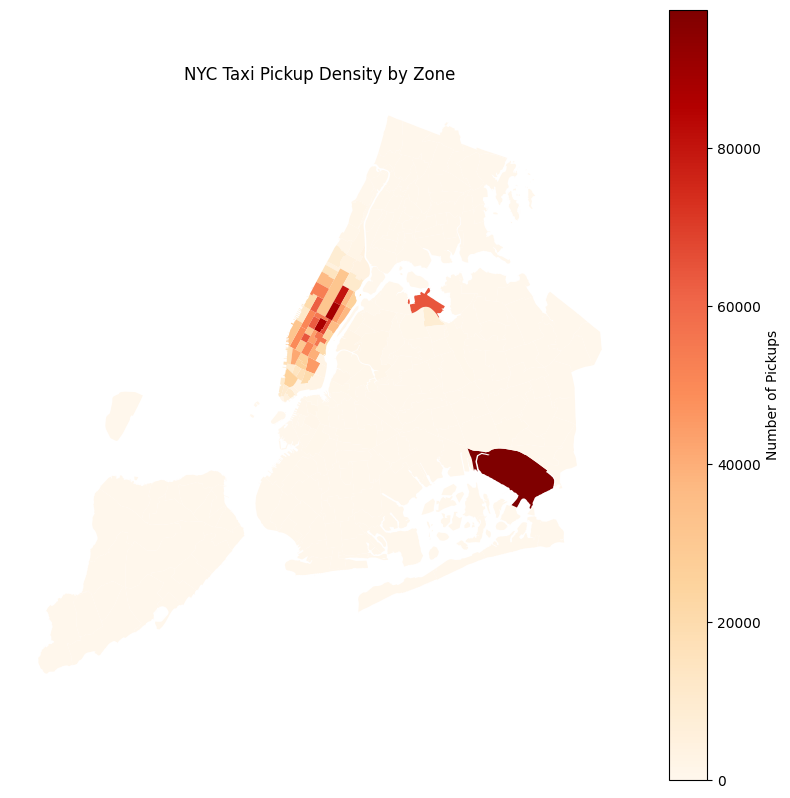

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
zones.plot(
    column="trip_count",
    ax=ax,
    legend=True,
    cmap="OrRd",
    legend_kwds={"label": "Number of Pickups"}
)

ax.set_title("NYC Taxi Pickup Density by Zone")
ax.axis("off")
plt.show()


### Spatial Demand Insight

Taxi demand is highly concentrated in central Manhattan and airport zones.
Outer boroughs show significantly lower pickup density, indicating
opportunities for better cab repositioning and dynamic dispatch strategies.


In [23]:
# Extract time-based features
taxi_df["pickup_hour"] = taxi_df["tpep_pickup_datetime"].dt.hour
taxi_df["pickup_day"] = taxi_df["tpep_pickup_datetime"].dt.day_name()
taxi_df["pickup_month"] = taxi_df["tpep_pickup_datetime"].dt.month


<Axes: title={'center': 'Hourly Taxi Demand'}, xlabel='pickup_hour'>

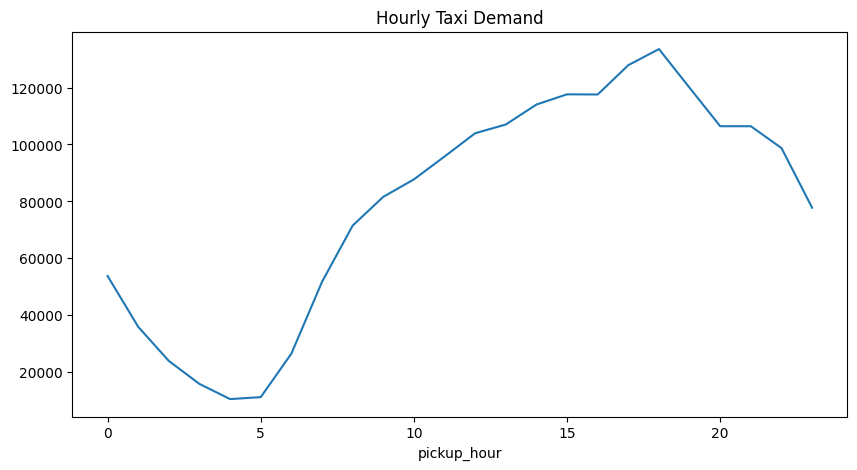

In [24]:
hourly_trips = taxi_df.groupby("pickup_hour").size()

hourly_trips.plot(
    kind="line",
    figsize=(10,5),
    title="Hourly Taxi Demand"
)


### Hourly Demand Insight

Taxi demand peaks during morning (7–10 AM) and evening (4–8 PM) commute hours.
Lower demand is observed during late-night and early-morning periods.


<Axes: title={'center': 'Weekday vs Weekend Taxi Demand'}>

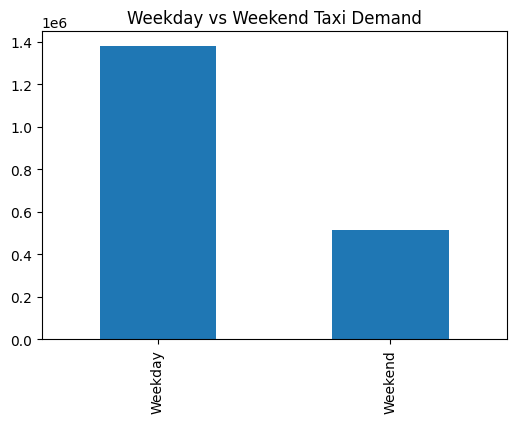

In [25]:
taxi_df["is_weekend"] = taxi_df["pickup_day"].isin(["Saturday", "Sunday"])

weekday_trips = taxi_df.groupby("is_weekend").size()
weekday_trips.index = ["Weekday", "Weekend"]

weekday_trips.plot(
    kind="bar",
    figsize=(6,4),
    title="Weekday vs Weekend Taxi Demand"
)


### Weekday vs Weekend Insight

Taxi demand is higher on weekdays due to office commuting.
Weekend demand is lower but more evenly distributed throughout the day.


<Axes: title={'center': 'Monthly Taxi Demand (2023)'}, xlabel='pickup_month'>

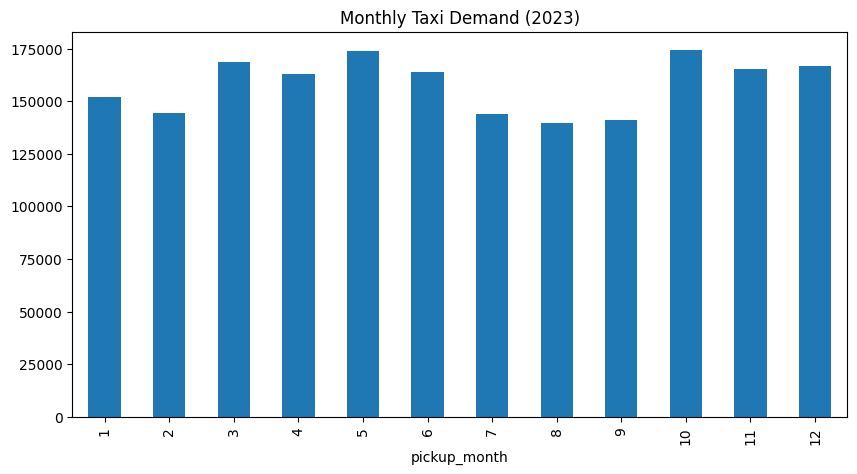

In [26]:
monthly_trips = taxi_df.groupby("pickup_month").size()

monthly_trips.plot(
    kind="bar",
    figsize=(10,5),
    title="Monthly Taxi Demand (2023)"
)


### Seasonal Demand Insight

Taxi demand shows seasonal variation, with increased activity during
summer and year-end months, likely driven by tourism and holidays.


<Axes: title={'center': 'Monthly Revenue Trend (Fare Amount)'}, xlabel='pickup_month'>

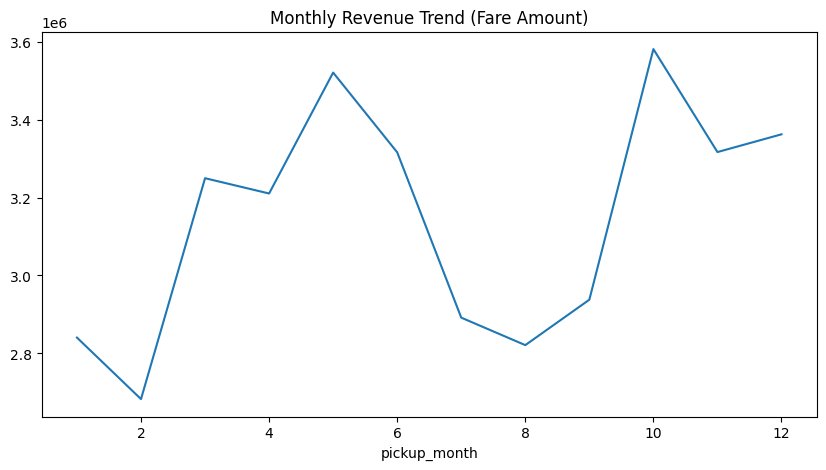

In [27]:
monthly_revenue = taxi_df.groupby("pickup_month")["fare_amount"].sum()

monthly_revenue.plot(
    kind="line",
    figsize=(10,5),
    title="Monthly Revenue Trend (Fare Amount)"
)


### Revenue Insight

Monthly revenue trends closely follow demand patterns,
with peak revenue observed during high-demand travel seasons.


<Axes: title={'center': 'Day vs Night Revenue'}>

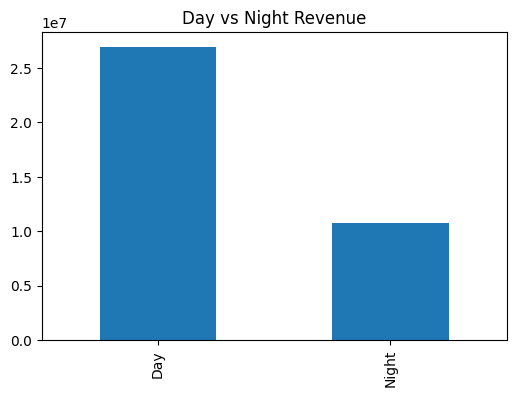

In [28]:
taxi_df["is_night"] = taxi_df["pickup_hour"].between(20, 23) | taxi_df["pickup_hour"].between(0, 5)

night_revenue = taxi_df.groupby("is_night")["fare_amount"].sum()
night_revenue.index = ["Day", "Night"]

night_revenue.plot(
    kind="bar",
    figsize=(6,4),
    title="Day vs Night Revenue"
)


### Day vs Night Revenue Insight

Night-time trips contribute disproportionately higher revenue per trip,
likely due to longer distances, surcharges, and reduced traffic congestion.


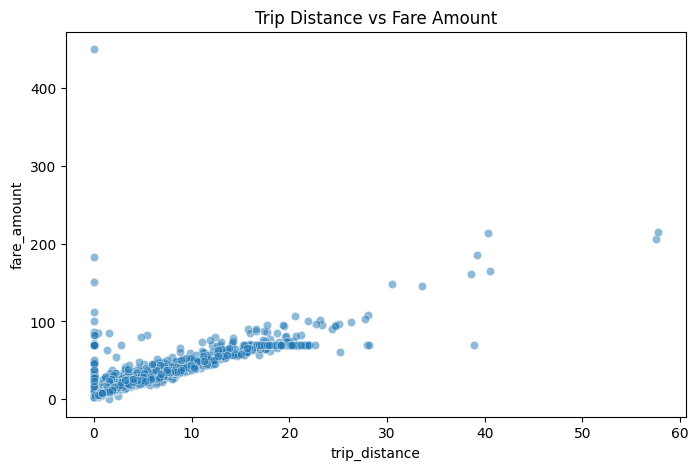

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.scatterplot(
    data=taxi_df.sample(min(5000, len(taxi_df)), random_state=42),
    x="trip_distance",
    y="fare_amount",
    alpha=0.5
)
plt.title("Trip Distance vs Fare Amount")
plt.show()


### Distance vs Fare Insight

Fare amount increases proportionally with trip distance,
confirming distance-based fare calculation logic.


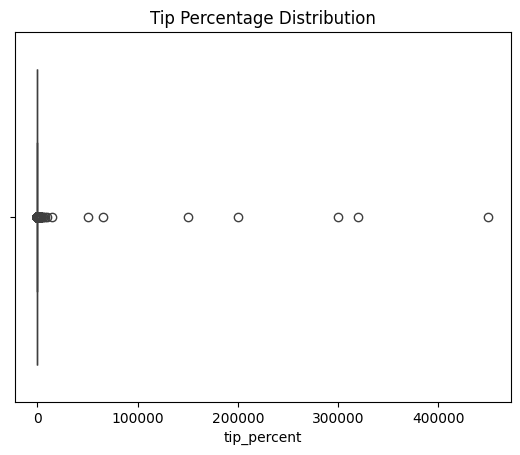

In [30]:
taxi_df["tip_percent"] = (taxi_df["tip_amount"] / taxi_df["fare_amount"]) * 100

sns.boxplot(x=taxi_df["tip_percent"])
plt.title("Tip Percentage Distribution")
plt.show()


### Tipping Behavior Insight

Tip percentages vary widely, with higher tips generally associated
with longer trips and digital payment methods.


## 4. Conclusion and Business Recommendations

### Conclusion

This exploratory data analysis examined NYC Yellow Taxi trip data for the year 2023
to identify demand patterns, revenue drivers, spatial concentration, and passenger
behavior. The analysis revealed strong temporal trends, with demand peaking during
weekday commuting hours and seasonal variation observed across months. Spatial
analysis highlighted significant concentration of taxi pickups in central Manhattan
and airport zones, while outer boroughs showed comparatively lower demand.

Revenue analysis demonstrated that night-time trips contribute a higher revenue per
trip, and fare amounts scale proportionally with trip distance. Tipping behavior was
found to vary widely, with higher tips associated with longer trips and digital
payment methods. Overall, the findings highlight opportunities for operational
optimization through data-driven decision-making.

---

### Business Recommendations

#### 1. Routing and Dispatch Optimization
- Increase taxi availability during peak morning and evening commute hours.
- Avoid consistently slow and congested routes identified through speed analysis.
- Use historical demand patterns to support predictive and dynamic dispatching.

#### 2. Strategic Cab Positioning
- Pre-position taxis in high-demand zones such as central Manhattan and airport areas.
- Improve cab repositioning strategies in zones with pickup–drop-off imbalance.
- Deploy additional vehicles to nightlife zones during night hours.

#### 3. Pricing and Revenue Optimization
- Introduce dynamic pricing based on time-of-day and demand intensity.
- Encourage digital payment adoption to improve tipping behavior.
- Optimize fare structures for long-distance and night-time trips to maximize revenue.

---

### Assumptions

- Sampled data accurately represents overall 2023 travel patterns.
- Fare structures remained consistent throughout the year.
- Extreme values reflect real-world scenarios such as long trips or traffic delays.
- Traffic conditions are assumed to be stable within comparable time windows.

---

### Final Remarks

This analysis demonstrates how exploratory data analysis can uncover actionable
insights from large-scale transportation datasets. By leveraging these insights,
taxi operators can improve fleet utilization, enhance passenger experience, and
maximize operational efficiency.
